In [1]:
# +----------------------------------------------------------------------------+
# |                                                                            |
# |       .-"""""""-.             ___                                          |
# |     .'           '.       _,~"                                             |
# |    /          .##.  \   ,~"                                                |
# |   |           '##'  |~"                                                    |
# |    \                /~,                                                    |
# |     '.            .'   "~,_                                                |
# |       '-........-'        "~,__                                            |
# |                                                                            |
# | Author    : Yatharth Bhasin (yatharth1997+ts@gmail.com)                    |
# | Date      : November 2026                                                  |
# | Copyright (c) 2026 Yatharth Bhasin                                         |
# | License-Identifier: MIT                                                    |
# +----------------------------------------------------------------------------+

# Fleet clock synchronization

How far apart are the scopes' clocks? A disturbance recorded on several scopes can only be lined up in time if
their clocks agree. This notebook puts a bound on the clock difference between any two scopes, from repeated
runs. The clocks are not made perfect; their error is measured.

*Analysis written by Claude (Anthropic); conceptualised and verified by Yatharth Bhasin.*

## Protocol

Acquisition: [`scripts/debug/fleet_clock_synchronization.py`](https://github.com/Trappy-Scopes/trappyscopes/blob/main/scripts/debug/fleet_clock_synchronization.py).
One NTP server gives time to every scope over the wired network. Each scope runs [chrony](https://chrony-project.org)
with that server as its only time source; `install_requirements()` sets this up once per scope. Each run then
logs what chrony measures for 2 h, and the runs on all scopes overlap. The whole run is repeated at least three
times (N ≥ 3). As in Lab Streaming Layer, clock offsets
are measured and stored next to the data, and the error is worked out afterwards.

Recommended: make sure the NTP server is itself well synchronized before the run.

**Running in Colab.** Open this notebook with the *Open in Colab* button on its page. The next cell runs only
in Colab: it installs what Colab lacks and asks for a `.zip` of your experiment folders.

In [2]:
import os, subprocess, sys
if "google.colab" in sys.modules:                         # skipped everywhere else
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "trappy-explorer @ git+https://github.com/Trappy-Scopes/trappy-explorer.git"], check=True)
    from google.colab import files
    for name in files.upload():                           # a .zip of your experiment folders
        subprocess.run(["unzip", "-q", "-o", name, "-d", "/content/data"], check=True)
    root = "/content/data"
    while True:                                           # step into a single wrapping folder
        subs = [d for d in os.listdir(root) if not d.startswith(("__MACOSX", "."))]
        if len(subs) == 1 and not os.path.exists(os.path.join(root, subs[0], "experiment.yaml")):
            root = os.path.join(root, subs[0])
        else:
            break
    os.environ["CALIBRATION_DATA"] = root

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import rich, yaml
from explorer.legacy import ExpExplorer

DATA = os.environ.get("CALIBRATION_DATA", "/Users/byatharth/data")   # set to your own runs
SETS = ["debugging/2026_11_16_fleet_clock_sync_test2",                  # one folder of runs per repeat
        "debugging/2026_11_16_fleet_sync_test3",
        "2026_11_24_clock_test3/2026_11_24"]
if "CALIBRATION_DATA" in os.environ:                    # Colab: every folder of runs in the upload is a repeat
    has_runs = lambda d: any(os.path.isfile(os.path.join(d, x, "experiment.yaml")) for x in os.listdir(d))
    SETS = ["."] if has_runs(DATA) else sorted(
        d for d in os.listdir(DATA) if os.path.isdir(os.path.join(DATA, d)) and has_runs(os.path.join(DATA, d)))
OUT = "results"                                        # the fleet table is written here
ACCEPT_MS = 4.0                                        # largest allowed clock difference, two scopes
TICK_S = 10                                            # tracking_period_s of the script
SCOPES = [f"M{i}" for i in range(1, 9)]
ERR = {"utc": "#eb6834", "limit": "#52514e"}
REP = dict(zip([f"R{i + 1}" for i in range(len(SETS))],
               ["#2a78d6", "#1baf7a", "#eda100", "#6250d6", "#e87ba4", "#008300"]))   # one colour per repeat
sns.set_theme(style="ticks", rc={"axes.grid": True, "grid.color": "#e8e8e6",
                                 "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                                 "lines.linewidth": 1.2, "legend.frameon": False})

## Data

The run is repeated: each repeat is one folder holding one run per scope. `SETS` lists the folders, oldest
first; below they are R1, R2, ... Runs are read with trappy-explorer's legacy reader,
`explorer.legacy.ExpExplorer`, in legacy mode: the script writes plain numbers only, so nothing is dropped.
Each run has four streams in `experiment.yaml`: `setup` (what the clock follows, at the start and the end),
`ntp` (one row per clock update from the NTP server), `pico` (the Pico's clock, once a minute) and `tandh`.

In [4]:
rich.get_console().quiet = True                           # the loader prints one line per run
exps = {r: ExpExplorer.create_superset(os.path.join(DATA, s)) for r, s in zip(REP, SETS)}
rich.get_console().quiet = False
print(exps["R1"])
print(pd.Series(SETS, index=list(exps), name="folder").to_string(), "\n")

res = []
for r, e in exps.items():
    ms = e.df_events.query("type == 'measurement_stream'")
    res.append(e.df.assign(rep=r, stream=e.df.measureid.map(dict(zip(ms.measureid, ms.name)))))
res = pd.concat(res, ignore_index=True)
res["wall"] = res.machinetime / 1e9                       # the scope's own clock, as in tracking.csv
res.columns = res.columns.str.replace("nas_", "server_")  # older column names

exp_of = {eid: e for e in exps.values() for eid in e.data}
setup = res[res.stream == "setup"].dropna(axis=1, how="all")
server_of = setup.sort_values("wall").drop_duplicates("eid").set_index("eid").server
runs = pd.DataFrame([{"rep": r, "scope": d["metadata"]["name"].split("__")[0], "eid": eid,
                      "started": d["metadata"]["created"], "server": server_of.get(eid)}
                     for r, e in exps.items() for eid, d in e.data.items()]).set_index(["rep", "scope"])
runs["hours"] = runs.eid.map(res.groupby("eid").wall.agg(lambda w: w.max() - w.min()) / 3600).round(2)
rows = res.groupby(["eid", "stream"]).size().unstack(fill_value=0)
runs = runs.join(rows.reindex(columns=["setup", "ntp", "pico", "tandh"], fill_value=0), on="eid").sort_index()
present = [s for s in SCOPES if s in runs.index.get_level_values("scope")]
scope_of, rep_of = runs.reset_index().set_index("eid").scope, runs.reset_index().set_index("eid").rep
runs

<Experiments :: 8  datasets>
  |- eid: fed3012801
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 69c7ae1ccc
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 67bace2a7f
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 2d3735125d
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: a3603baae8
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: a2188d631f
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 6511da1077
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 55240748de
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico

R1    debugging/2026_11_16_fleet_clock_sync_test2
R2          debugging/2026_11_16_fleet_sync_test3
R3              2026_1

eid                    started       server  hours  setup  \
rep scope                                                                     
R1  M1     fed3012801 2026-11-16 11:21:01.050134  192.168.1.1    2.0      2   
    M2     2d3735125d 2026-11-16 11:21:19.660231  192.168.1.1    2.0      2   
    M3     a2188d631f 2026-11-16 11:21:40.818856  192.168.1.1    2.0      2   
    M4     67bace2a7f 2026-11-16 11:22:09.420776  192.168.1.1    2.0      2   
    M5     6511da1077 2026-11-16 11:23:34.628991  192.168.2.1    2.0      2   
    M6     69c7ae1ccc 2026-11-16 11:23:55.979675  192.168.2.1    2.0      2   
    M7     55240748de 2026-11-16 11:24:18.468048  192.168.2.1    2.0      2   
    M8     a3603baae8 2026-11-16 11:24:42.458747  192.168.2.1    2.0      2   
R2  M1     d1cb2a8b99 2026-11-16 18:31:05.740148  192.168.1.1    2.0      2   
    M2     cc8cb59a91 2026-11-16 18:31:44.725297  192.168.1.1    2.0      2   
    M3     7977b63700 2026-11-16 18:32:06.982141  192.168.1.1    2.0      2   
    M4     2a2ffefaa9 2026-11-16 18:32:35.073093  192.168.1.1    2.0      2   
    M5     14233636c7 2026-11-16 18:32:58.109205  192.168.2.1    2.0      2   
    M6     7015bc3243 2026-11-16 18:33:26.652736  192.168.2.1    2.0      2   
    M7     ca6fd28c4f 2026-11-16 18:34:03.473425  192.168.2.1    2.0      2   
    M8     4a860772d0 2026-11-16 18:34:27.588139  192.168.2.1    2.0      2   
R3  M1     7e1da2fd96 2026-11-24 13:40:19.083144  192.168.1.1    2.0      2   
    M2     ec021731e7 2026-11-24 13:40:58.769119  192.168.1.1    2.0      2   
    M3     a8f3651586 2026-11-24 13:41:53.431686  192.168.1.1    2.0      2   
    M4     7ba9859c6e 2026-11-24 13:42:33.510523  192.168.1.1    2.0      2   
    M5     14a6437801 2026-11-24 13:43:19.677468  192.168.2.1    2.0      2   
    M6     ecc39da457 2026-11-24 13:44:02.096986  192.168.2.1    2.0      2   
    M7     3854e88e40 2026-11-24 13:44:37.732438  192.168.2.1    2.0      2   
    M8     8b6185bb4c 2026-11-24 13:45:15.230533  192.168.2.1    2.0      2   

           ntp  pico  tandh  
rep scope                    
R1  M1     189   121     25  
    M2     180   121     25  
    M3     179   121     25  
    M4     189   121     25  
    M5     190   121     25  
    M6     180   120     24  
    M7     163   121     25  
    M8     178   121     25  
R2  M1      87   121     25  
    M2      93   121     25  
    M3     101   121     25  
    M4      92   121     25  
    M5      77   121     25  
    M6      84   121     25  
    M7      69   121     25  
    M8     107   121     25  
R3  M1     175   121     25  
    M2     175   121     25  
    M3     145   121     25  
    M4     164   121     25  
    M5     172   121     25  
    M6     169   121     25  
    M7     175   121     25  
    M8     145   121     25

In [5]:
eid = runs.eid.iloc[0]                                    # one run's folder, as an example
tree = exp_of[eid].data[eid]["filetree"]["."]
print(os.path.basename(exp_of[eid].get_parent_dir(eid)))
for f in sorted(tree["files"]) + sorted(k + "/" for k in tree if k != "files"):
    print("   ", f)

print()
skip = {"eid", "type", "measureid", "measureidx", "mid", "sid", "scriptid", "success", "dt", "rep",
        "exptime", "attribs", "machinetime", "sessiontime", "scopeid", "stream", "wall"}
for name, g in res.groupby("stream"):
    cols = [c for c in g.dropna(axis=1, how="all").columns if c not in skip]
    print(f"{name:6s} {len(g):5d} rows   {', '.join(cols)}")

M1__YB__2026_11_16__11hh_21mm__fleet_clock_sync__fed3012801
    chrony.conf
    experiment.yaml
    fed3012801_tracking.csv
    logs.yaml
    sessions.yaml
    analysis/
    converted/
    postprocess/
    scripts/

ntp     3478 rows   clock_offset_s, max_error_s, server_leap, server_stratum, offset_s, freq_ppm, leap, peer_delay_s, peer_dispersion_s, poll_s, root_delay_s, root_dispersion_s, server_root_delay_s, server_root_dispersion_s, skew_ppm
pico    2903 rows   phase, error_s, offset_s, pico_time, wait_s, wire_s
setup     48 rows   chrony_active, chrony_version, clock_offset_s, iface, local_addr, max_error_s, n_sources, ntp_synchronized, phase, route_dev, rx_timestamping, server, server_leap, server_stratum, sign_check, sources, timesyncd
tandh    599 rows   humidity, temp


Each run folder also holds `<eid>_tracking.csv`: chrony's state every 10 s (`chronyc tracking`), taken on the
same wall-clock seconds on every scope, so rows from different scopes line up. Offsets are positive when the
scope's clock is ahead.

First, check that each run was set up as intended: one time source, reached over the cable, the old time
service off, and the offset sign confirmed on the scope (`sign_check`, expected `agree`). chrony's `ntpdata`
reports the offset with the opposite sign; runs recorded before the script flipped it (test 1, 2026-11-15) show
`OPPOSITE`, and their offsets are flipped below. `differ` means chrony had not yet used the last exchange.

In [6]:
checks = setup.assign(rep=setup.eid.map(rep_of), scope=setup.eid.map(scope_of)).sort_values("wall")
once = checks.groupby(["rep", "scope"])[["server", "sources", "route_dev", "timesyncd", "rx_timestamping"]].last()
both = checks.set_index(["rep", "scope", "phase"])[["ntp_synchronized", "sign_check"]].unstack("phase")
both = both.reindex(columns=["start", "end"], level="phase")
both.columns = [f"{c} ({p})" for c, p in both.columns]
once.join(both)

server      sources route_dev timesyncd rx_timestamping  \
rep scope                                                                 
R1  M1     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M2     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M3     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M4     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M5     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
    M6     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
    M7     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
    M8     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
R2  M1     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M2     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M3     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M4     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M5     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
    M6     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
    M7     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
    M8     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
R3  M1     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M2     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M3     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M4     192.168.1.1  192.168.1.1      eth0  inactive          Kernel   
    M5     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
    M6     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
    M7     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   
    M8     192.168.2.1  192.168.2.1      eth0  inactive          Kernel   

          ntp_synchronized (start) ntp_synchronized (end)  \
rep scope                                                   
R1  M1                         yes                    yes   
    M2                         yes                    yes   
    M3                         yes                    yes   
    M4                         yes                    yes   
    M5                         yes                    yes   
    M6                         yes                    yes   
    M7                         yes                    yes   
    M8                         yes                    yes   
R2  M1                         yes                    yes   
    M2                         yes                    yes   
    M3                         yes                    yes   
    M4                         yes                    yes   
    M5                         yes                    yes   
    M6                         yes                    yes   
    M7                         yes                    yes   
    M8                         yes                    yes   
R3  M1                         yes                    yes   
    M2                         yes                    yes   
    M3                         yes                    yes   
    M4                         yes                    yes   
    M5                         yes                    yes   
    M6                         yes                    yes   
    M7                         yes                    yes   
    M8                         yes                    yes   

                                      sign_check (start)  \
rep scope                                                  
R1  M1     differ (ntpdata -0.000186, sources -0.000008)   
    M2                                             agree   
    M3     differ (ntpdata -0.000187, sources -0.000022)   
    M4     differ (ntpdata -0.000202, sources -0.000063)   
    M5     differ (ntpdata -0.000270, sources -0.000019)   
    M6     differ (ntpdata -0.000183, sources -0.000030)  

## Maximum error

chrony bounds how far the scope's clock can be from true time (UTC):

    max error = |offset| + root dispersion + root delay / 2

Most of it is the NTP server's own distance from UTC, which is the same for every scope and cancels between
two scopes. The server's own root delay (`server_root_delay_s`) is removed. Its root dispersion is kept: chrony
reports the root dispersion of the sample it trusts most, often an older one, while the server's dispersion grows
between its own updates, so the latest `server_root_dispersion_s` is too large to subtract (in tests 1 and 2 that
gave a negative error 41-75% of the time). The error against the NTP server is then an upper bound, high by the
server's root dispersion (0.3-2.2 ms in tests 1 and 2):

    error to server = |offset| + root dispersion + (root delay - server root delay) / 2

In [7]:
ntp = res[res.stream == "ntp"].dropna(axis=1, how="all").copy()
old_sign = setup[setup.sign_check.astype(str).str.startswith("OPPOSITE")].eid.unique()
ntp.loc[ntp.eid.isin(old_sign), "offset_s"] *= -1        # recorded before the script fixed the sign
ntp = ntp.assign(scope=ntp.eid.map(scope_of), rep=ntp.eid.map(rep_of))
tr = pd.concat([pd.read_csv(f"{exp_of[e].get_parent_dir(e)}/{e}_tracking.csv").assign(eid=e)
                for e in runs.eid]).sort_values("wall")
last = ntp[["eid", "wall", "server_root_delay_s"]].sort_values("wall")
last["server_root_delay_s"] = last.groupby("eid").server_root_delay_s.cummin()  # never remove too much
tr = pd.merge_asof(tr, last, on="wall", by="eid", direction="backward")
tr["err_server_s"] = (tr.clock_offset_s.abs() + tr.root_dispersion_s
                      + (tr.root_delay_s - tr.server_root_delay_s) / 2)
tr = tr.dropna(subset=["err_server_s"])                  # before the run's first clock update
tr = tr.assign(scope=tr.eid.map(scope_of), rep=tr.eid.map(rep_of))
tr["hours"] = (tr.wall - tr.groupby("rep").wall.transform("min")) / 3600   # since the repeat began

Each scope's maximum error against the NTP server, one line per repeat, against the time since the repeat
began. The faint orange lines are the error against UTC. The dashed line is the acceptable error for one scope,
half of `ACCEPT_MS`: two scopes that both stay below it differ by less than `ACCEPT_MS`. A slow ramp means the
scope lost its NTP server for a while; a narrow peak is one slow network exchange.

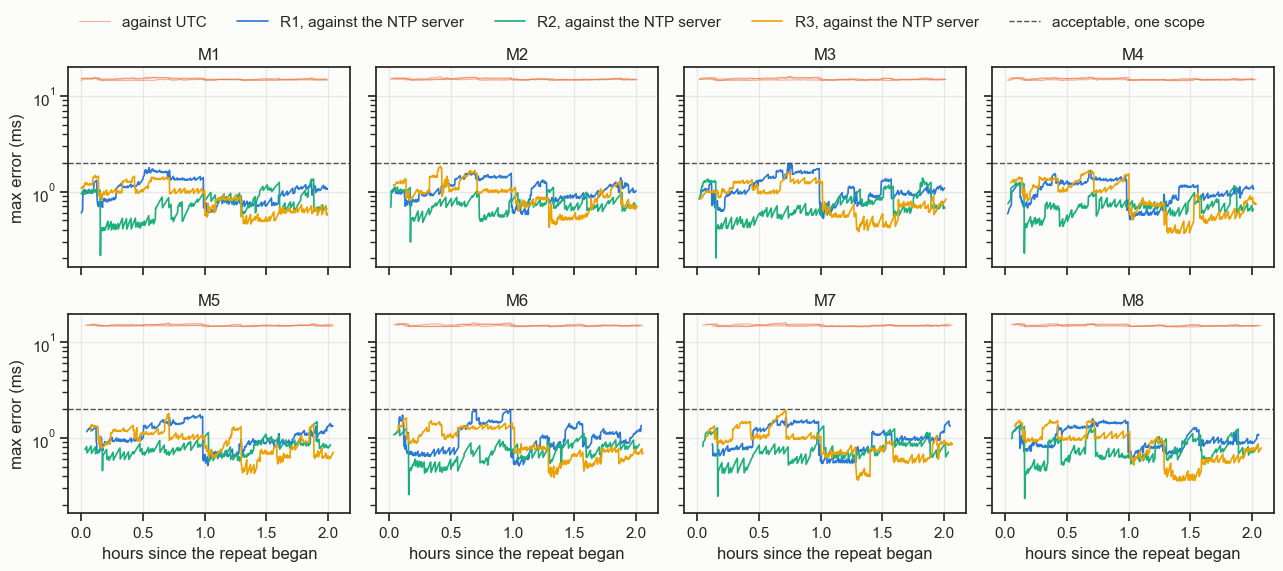

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, s in zip(axes.flat, SCOPES):
    for r, d in tr[tr.scope == s].groupby("rep"):
        ax.plot(d.hours, 1e3 * d.max_error_s, color=ERR["utc"], lw=0.8, alpha=0.5, label="against UTC")
        ax.plot(d.hours, 1e3 * d.err_server_s, color=REP[r], label=f"{r}, against the NTP server")
    ax.axhline(ACCEPT_MS / 2, color=ERR["limit"], ls="--", lw=1, label="acceptable, one scope")
    ax.set(yscale="log", title=s)
for ax in axes[:, 0]:
    ax.set_ylabel("max error (ms)")
for ax in axes[1]:
    ax.set_xlabel("hours since the repeat began")
handles = {l: h for ax in axes.flat for h, l in zip(*ax.get_legend_handles_labels())}
fig.legend(handles.values(), handles.keys(), loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.05))
fig.tight_layout()

## Scope to scope

At every 10 s tick, two scopes' clocks differ by at most the sum of their errors against the NTP server. Over the
time all runs of a repeat overlap, each map shows the value this bound stays below 99% of the time, one map per
repeat. This holds when every server address belongs to the same NTP server, as here; otherwise compare against
UTC instead.

The colour scale runs from 0 to the acceptance limit (`ACCEPT_MS`). The differences between pairs are not a
property of the scopes: they do not repeat from one repeat to the next. What holds for the fleet is the **fleet
bound**, in the table below the maps: at each tick, any two scopes differ by at most the sum of the two largest
errors at that tick; the fleet bound is its 99th percentile over the repeat.

,folder,scopes,shared_h,fleet_bound_ms
R1,debugging/2026_11_16_fleet_clock_sync_test2,8,1.875,3.605
R2,debugging/2026_11_16_fleet_sync_test3,8,1.939,2.639
R3,2026_11_24_clock_test3/2026_11_24,8,1.917,3.480


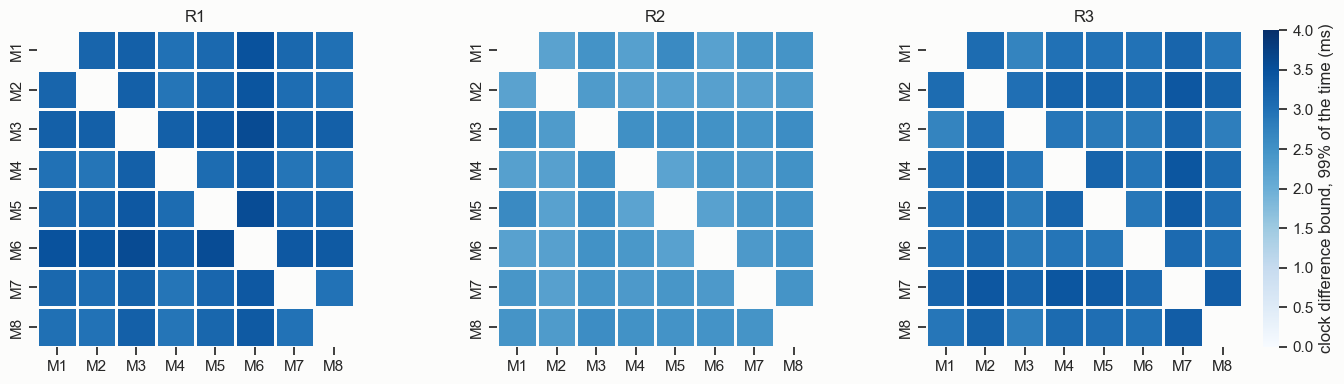

In [9]:
tr["tick"] = (tr.wall / TICK_S).round().astype(int)      # the shared grid
pair, bounds = {}, {}
for r, g in tr.groupby("rep"):
    cols = [s for s in SCOPES if s in set(g.scope)]
    E = g.pivot_table(index="tick", columns="scope", values="err_server_s")[cols].dropna()
    pair[r] = pd.DataFrame({a: {b: np.percentile(E[a] + E[b], 99) if a != b else np.nan
                                for b in cols} for a in cols}).loc[cols, cols]
    bounds[r] = {"folder": SETS[list(REP).index(r)], "scopes": len(cols), "shared_h": len(E) * TICK_S / 3600,
                 "fleet_bound_ms": 1e3 * np.percentile(np.sort(E.values, axis=1)[:, -2:].sum(axis=1), 99)}
bounds = pd.DataFrame(bounds).T.astype({"scopes": int, "shared_h": float, "fleet_bound_ms": float})

top = max(ACCEPT_MS, 1e3 * max(p.max().max() for p in pair.values()))
fig, axes = plt.subplots(1, len(pair), figsize=(4.4 * len(pair) + 1, 4), squeeze=False)
for i, (ax, (r, p)) in enumerate(zip(axes[0], pair.items())):
    sns.heatmap(1e3 * p, cmap="Blues", square=True, linewidths=2, linecolor="#fcfcfb", vmin=0, vmax=top,
                cbar=i == len(pair) - 1, ax=ax,
                cbar_kws={"label": "clock difference bound, 99% of the time (ms)"})
    ax.set(xlabel="", ylabel="", title=r)
    ax.grid(False)
fig.tight_layout()
bounds.round(3)

## Each NTP exchange

Every clock update: the offset measured to the NTP server, and the round-trip network delay to it, per scope and
coloured by repeat (each scope's server address is in the runs table). The delay shows the quality of each
scope's network path; large offsets come from slow exchanges.

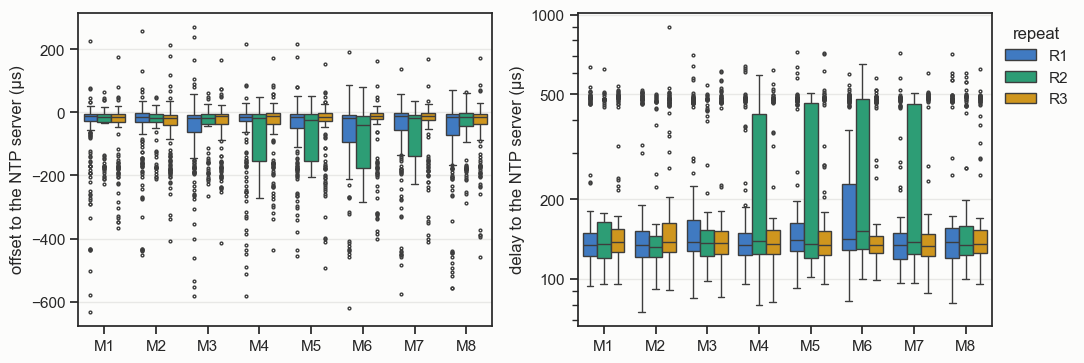

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, label in zip(axes, ["offset_s", "peer_delay_s"],
                          ["offset to the NTP server (µs)", "delay to the NTP server (µs)"]):
    sns.boxplot(ntp.assign(v=1e6 * ntp[col]), x="scope", y="v", hue="rep", order=present,
                hue_order=list(exps), palette=REP, fliersize=2, linewidth=1, ax=ax, legend=ax is axes[1])
    ax.set(xlabel="", ylabel=label)
axes[1].set_yscale("log")
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1, 1), title="repeat")
axes[1].yaxis.set_major_locator(mticker.LogLocator(subs=(1.0, 2.0, 5.0)))
axes[1].yaxis.set_major_formatter(mticker.ScalarFormatter())
axes[1].yaxis.set_minor_formatter(mticker.NullFormatter())
fig.tight_layout()

## The Pico's clock

Each scope's Pico keeps its own clock, and nothing synchronizes it. The run reads it once a minute over the
serial link: as found for the first 5 min, then sets it once to the scope's time (UTC) and follows it. Each
reading is a request and reply timed to the moment the Pico's seconds tick over, with an error of a few ms
(`error_s`). This is for information and is not part of the acceptance. A Pico keeps its clock until it loses
power, so it is found either as set by an earlier run, or restarted at 2021-01-01 (about -1.85e8 s).

As found: the board, whether its clock counts fractions of a second, and how far its clock was off at the start
of each repeat (`found_s`, + = ahead).

In [11]:
pico = res[res.stream == "pico"].dropna(axis=1, how="all").sort_values("wall")
pico = pico.assign(scope=pico.eid.map(scope_of), rep=pico.eid.map(rep_of))
info = pd.concat(e.df_events.query("type == 'pico_check'") for e in exps.values())
info = info.assign(scope=info.eid.map(scope_of)).groupby("scope")[
    ["machine", "micropython", "time_ns_subsecond"]].last()
found = pico[pico.phase == "as_found"].groupby(["scope", "rep"]).offset_s.first().unstack("rep")
info.join(found.round(3).astype(str).add_prefix("found_s ")).reindex(present)   # plain seconds

,machine,micropython,time_ns_subsecond,found_s R1,found_s R2,found_s R3
scope,,,,,,
M1,Raspberry Pi Pico W with RP2040,1.24.1,True,0.831,-0.064,-185983489.303
M2,Raspberry Pi Pico W with RP2040,1.24.1,True,0.734,-0.1,-185982449.897
M3,Raspberry Pi Pico W with RP2040,1.24.1,True,0.721,-0.104,-185985901.985
M4,Raspberry Pi Pico W with RP2040,1.24.1,True,0.523,-0.171,-185991187.105
M5,Raspberry Pi Pico W with RP2040,1.23.0,True,-185297501.937,-0.121,-185726546.114
M6,Raspberry Pi Pico W with RP2040,1.24.0,True,-185300541.376,-0.129,-186068137.111
M7,Raspberry Pi Pico W with RP2040,1.24.0,True,0.738,-0.102,-185726792.488
M8,Raspberry Pi Pico W with RP2040,1.24.0,True,0.76,-0.087,-185726462.465


After the set. Left: how far each Pico's clock moved away from its scope's clock, one line per Pico and repeat;
the slope is the drift (10 ppm is 36 ms per hour). The orange band is how far apart two scopes' clocks can be
(the largest fleet bound of the repeats). The grey bar is the worst-case error of one reading (median; half the
serial round trip, so loose: the points scatter much less). A line that stops early is a Pico that stopped
answering. Right: each Pico's drift in each repeat. Dots that sit together mean a steady drift, which can be
corrected for afterwards.

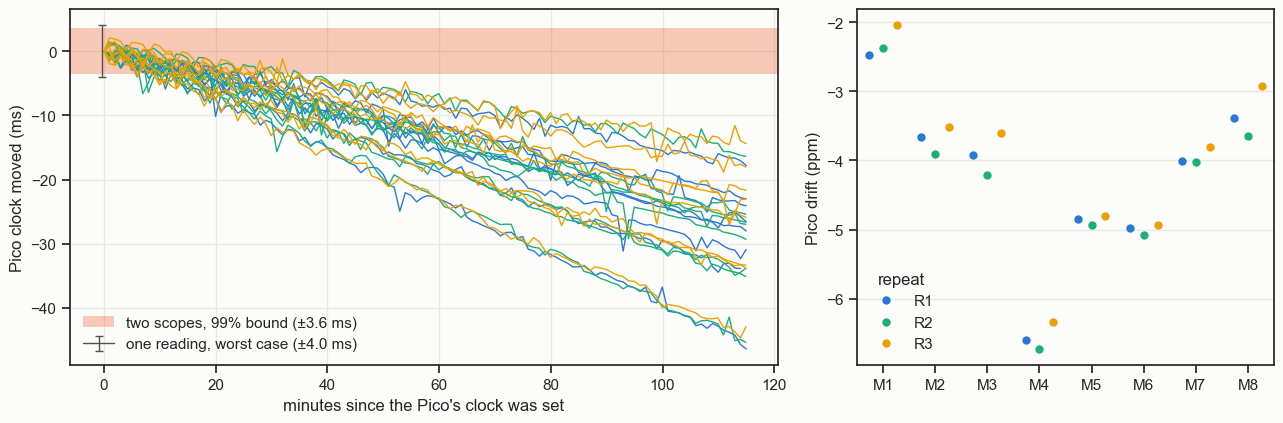

In [12]:
after = pico[pico.phase == "after_set"].copy()
first = after.groupby(["rep", "scope"])
after["minutes"] = (after.wall - first.wall.transform("first")) / 60
after["moved_ms"] = 1e3 * (after.offset_s - first.offset_s.transform("first"))
drift = after.groupby(["rep", "scope"])[["wall", "offset_s"]].apply(
    lambda d: 1e6 * np.polyfit(d.wall - d.wall.iloc[0], d.offset_s, 1)[0]).rename("ppm")

band = bounds.fleet_bound_ms.max()
fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.7, 1]})
ax.axhspan(-band, band, color=ERR["utc"], alpha=0.35, lw=0, label=f"two scopes, 99% bound (±{band:.1f} ms)")
for (r, s), d in after.groupby(["rep", "scope"]):
    ax.plot(d.minutes, d.moved_ms, color=REP[r], lw=1)
e = 1e3 * after.error_s.median()
ax.errorbar(-0.4, 0, yerr=e, color=ERR["limit"], capsize=3, lw=1, label=f"one reading, worst case (±{e:.1f} ms)")
ax.set(xlabel="minutes since the Pico's clock was set", ylabel="Pico clock moved (ms)")
ax.legend(loc="lower left")
sns.stripplot(drift.reset_index(), x="scope", y="ppm", hue="rep", order=present, hue_order=list(exps),
              palette=REP, dodge=True, jitter=False, size=6, ax=bx)
bx.set(xlabel="", ylabel="Pico drift (ppm)")
bx.legend(title="repeat", loc="lower left")
fig.tight_layout()

## Results

Per run: one row per repeat and scope, also written next to each run's data
(`analysis/fleet_clock_synchronization.yaml`). `err_*_ms` is the error against the NTP server (the upper bound
above); `utc_p99_ms` is chrony's own bound against UTC; `longest_gap_s` is the longest time between two clock
updates; `accepted`: the scope's own error stays below `ACCEPT_MS` / 2 for 99% of the run. `pico_*`: how far off
the Pico's clock was as found (s, + = ahead), its offset right after it was set (ms), its drift (ppm) and how far
it moved after the set (ms). `fleet_bound_ms` is the repeat's fleet bound.

In [13]:
q = lambda p: (lambda x: 1e3 * x.quantile(p))
per_run = runs[["eid", "server"]].join(tr.groupby(["rep", "scope"]).agg(
    err_p50_ms=("err_server_s", q(0.5)), err_p99_ms=("err_server_s", q(0.99)),
    err_max_ms=("err_server_s", q(1.0)), utc_p99_ms=("max_error_s", q(0.99))))
n = ntp.sort_values("wall").groupby(["rep", "scope"])
per_run["delay_p50_us"] = 1e6 * n.peer_delay_s.median()
per_run["offset_p99_us"] = 1e6 * n.offset_s.apply(lambda x: x.abs().quantile(0.99))
per_run["longest_gap_s"] = n.wall.apply(lambda w: w.diff().max())
per_run["accepted"] = per_run.err_p99_ms < ACCEPT_MS / 2
per_run["pico_found_s"] = found.stack().swaplevel()
per_run["pico_set_ms"] = 1e3 * after.groupby(["rep", "scope"]).offset_s.first()
per_run["pico_drift_ppm"] = drift
per_run["pico_moved_max_ms"] = after.groupby(["rep", "scope"]).moved_ms.apply(lambda x: x.abs().max())
per_run["fleet_bound_ms"] = bounds.fleet_bound_ms.reindex(per_run.index.get_level_values("rep")).values

for (r, s), row in per_run.iterrows():                    # one copy next to each run's data
    path = exp_of[row.eid].get_analysis_dir(row.eid)
    os.makedirs(path, exist_ok=True)
    with open(os.path.join(path, "fleet_clock_synchronization.yaml"), "w") as f:
        yaml.safe_dump({"rep": r, "scope": s, **{k: (v.item() if hasattr(v, "item") else v)
                                                 for k, v in row.items()}}, f)
per_run.round(3).astype({"pico_found_s": str})

eid       server  err_p50_ms  err_p99_ms  err_max_ms  \
rep scope                                                                
R1  M1     fed3012801  192.168.1.1       1.027       1.677       1.777   
    M2     2d3735125d  192.168.1.1       1.003       1.557       1.595   
    M3     a2188d631f  192.168.1.1       1.003       1.824       1.981   
    M4     67bace2a7f  192.168.1.1       1.067       1.531       1.658   
    M5     6511da1077  192.168.2.1       0.966       1.694       1.742   
    M6     69c7ae1ccc  192.168.2.1       0.994       1.915       1.934   
    M7     55240748de  192.168.2.1       0.970       1.532       1.616   
    M8     a3603baae8  192.168.2.1       0.909       1.506       1.580   
R2  M1     d1cb2a8b99  192.168.1.1       0.741       1.307       1.354   
    M2     cc8cb59a91  192.168.1.1       0.729       1.090       1.114   
    M3     7977b63700  192.168.1.1       0.672       1.318       1.377   
    M4     2a2ffefaa9  192.168.1.1       0.697       1.209       1.238   
    M5     14233636c7  192.168.2.1       0.772       1.398       1.473   
    M6     7015bc3243  192.168.2.1       0.734       1.210       1.249   
    M7     ca6fd28c4f  192.168.2.1       0.716       1.261       1.332   
    M8     4a860772d0  192.168.2.1       0.710       1.309       1.378   
R3  M1     7e1da2fd96  192.168.1.1       0.911       1.435       1.474   
    M2     ec021731e7  192.168.1.1       0.965       1.758       1.832   
    M3     a8f3651586  192.168.1.1       0.844       1.550       1.625   
    M4     7ba9859c6e  192.168.1.1       0.849       1.607       1.662   
    M5     14a6437801  192.168.2.1       0.941       1.556       1.799   
    M6     ecc39da457  192.168.2.1       0.807       1.528       1.618   
    M7     3854e88e40  192.168.2.1       0.886       1.850       1.931   
    M8     8b6185bb4c  192.168.2.1       0.904       1.504       1.534   

           utc_p99_ms  delay_p50_us  offset_p99_us  longest_gap_s  accepted  \
rep scope                                                                     
R1  M1         15.654       134.911        513.064        159.998      True   
    M2         15.534       134.182        437.992        180.002      True   
    M3         15.801       138.451        540.259        190.000      True   
    M4         15.508       134.629        494.305        160.002      True   
    M5         15.671       140.284        386.868        159.996      True   
    M6         15.892       141.810        451.361        130.004      True   
    M7         15.509       134.220        467.410        199.998      True   
    M8         15.483       137.603        527.676        170.002      True   
R2  M1         15.383       135.047        214.253        199.999      True   
    M2         15.344       132.197        205.299        200.008      True   
    M3         15.565       137.194        226.789        200.006      True   
    M4         15.469       139.722        228.436        200.004      True   
    M5         15.474       136.004        202.161        200.001      True   
    M6         15.469       151.810        256.921        200.006      True   
    M7         15.456       137.797        217.247        260.000      True   
    M8         15.568       134.051        257.689        190.003      True   
R3  M1         15.511       138.244        346.884        130.006      True   
    M2         15.834       138.259        328.959        130.001      True   
    M3         15.626       137.023        248.339        199.996      True   
    M4         15.683       135.388        326.297        190.003      True   
    M5         15.632       134.130        402.905        159.997      True   
    M6         15.604       134.885        379.466        199.994      True   
    M7         15.926       133.167        393.607        170.005      True   
    M8         15.580       136.106        393.411        199.968      True   

             pico_found_s  pico_set_ms

Per scope, over all repeats: the calibration result, exported to `results/`. Each value is the mean over the
repeats and `_sd` the standard deviation between them; `err_max_ms` is the largest of any repeat; `n` is the
number of repeats; `accepted` is true when the scope was accepted in every repeat.

In [14]:
by = per_run.groupby(level="scope")
mean = by[["err_p99_ms", "utc_p99_ms", "delay_p50_us", "pico_set_ms", "pico_drift_ppm"]].mean()
sd = by[["err_p99_ms", "pico_set_ms", "pico_drift_ppm"]].std().add_suffix("_sd")
fleet = mean.join(sd).assign(err_max_ms=by.err_max_ms.max(), n=by.size(), accepted=by.accepted.all())
fleet = fleet[["n", "err_p99_ms", "err_p99_ms_sd", "err_max_ms", "utc_p99_ms", "delay_p50_us", "pico_set_ms",
               "pico_set_ms_sd", "pico_drift_ppm", "pico_drift_ppm_sd", "accepted"]].reindex(present)
os.makedirs(OUT, exist_ok=True)
fleet.to_csv(f"{OUT}/fleet_clock_synchronization.csv")
fleet.round(3)

,n,err_p99_ms,err_p99_ms_sd,err_max_ms,utc_p99_ms,delay_p50_us,pico_set_ms,pico_set_ms_sd,pico_drift_ppm,pico_drift_ppm_sd,accepted
scope,,,,,,,,,,,
M1,3,1.473,0.188,1.777,15.516,136.067,0.089,1.050,-2.295,0.224,True
M2,3,1.468,0.342,1.832,15.571,134.880,-0.810,1.520,-3.697,0.198,True
M3,3,1.564,0.253,1.981,15.664,137.556,-0.123,0.762,-3.909,0.305,True
M4,3,1.449,0.211,1.662,15.554,136.580,-1.771,0.241,-6.557,0.199,True
M5,3,1.550,0.148,1.799,15.593,136.806,-0.388,1.128,-4.861,0.065,True
M6,3,1.551,0.353,1.934,15.655,142.835,-0.569,0.906,-4.993,0.074,True
M7,3,1.548,0.295,1.931,15.630,135.061,-0.691,0.299,-3.943,0.123,True
M8,3,1.440,0.113,1.580,15.544,135.920,-0.919,0.717,-3.320,0.366,True


## Acceptance

The fleet passes when the fleet bound, how far apart any two scopes' clocks can be for 99% of a repeat, stays
below `ACCEPT_MS` = 4 ms in every repeat. 4 ms is a tenth of one frame at 25 fps, so a disturbance seen on two
scopes falls in the same frame. Each scope's own share is `ACCEPT_MS` / 2: the dashed line in the first figure,
and `accepted` in the results.

In [15]:
fb = bounds.fleet_bound_ms
print(bounds.assign(passed=fb < ACCEPT_MS)[["folder", "fleet_bound_ms", "passed"]].round(3).to_string())
print(f"\nfleet bound over {len(fb)} repeats: {fb.mean():.3f} ± {fb.std():.3f} ms (mean ± SD), "
      f"limit {ACCEPT_MS} ms")
print("fleet:", "PASS" if (fb < ACCEPT_MS).all() else "FAIL")

                                         folder  fleet_bound_ms  passed
R1  debugging/2026_11_16_fleet_clock_sync_test2           3.605    True
R2        debugging/2026_11_16_fleet_sync_test3           2.639    True
R3            2026_11_24_clock_test3/2026_11_24           3.480    True

fleet bound over 3 repeats: 3.242 ± 0.525 ms (mean ± SD), limit 4.0 ms
fleet: PASS


## Persistent records

This calibration writes 0 records to the scope. Its set-up step, `install_requirements()`, does change the
scope's time service: chrony replaces systemd-timesyncd, with the NTP server as its only source. The run also
sets each Pico's clock to UTC once; the Pico loses that setting when it loses power.